# Лабораторная работа № 2. Интерпретация моделей Walmart


## 1. Загрузка библиотек и данных


In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

In [33]:
TARGET = 'Weekly_Sales'
DATE = 'Date'
data = pd.read_csv("Walmart_prepared.csv", parse_dates=[DATE])
if TARGET not in data or DATE not in data:
    raise ValueError(f'Ожидаются столбцы {TARGET!r} и {DATE!r}')
data = data.sort_values(DATE).reset_index(drop=True)
print(f'Файл: {"Walmart_prepared.csv"}')
print(f'Размер: {data.shape[0]:,} строк × {data.shape[1]} столбцов')
print(f'Даты: {data[DATE].min().date()} — {data[DATE].max().date()}')
print('Пропуски:', int(data.isna().sum().sum()))
data.head()

Файл: Walmart_prepared.csv
Размер: 5,848 строк × 87 столбцов
Даты: 2010-05-07 — 2012-10-26
Пропуски: 0


,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Holiday_New_Year,Holiday_Valentines_Day,Holiday_Super_Bowl,...,Store_40,Store_41,Store_42,Store_43,Store_44,Store_45,Quarter_1,Quarter_2,Quarter_3,Quarter_4
0,2010-05-07,1603955.12,0,72.55,2.835,210.339968,7.808,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,2010-05-07,1365552.28,0,61.04,2.981,132.106200,5.435,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,2010-05-07,1409705.03,0,66.65,3.095,132.106200,8.211,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2010-05-07,1619920.04,0,73.68,2.835,211.844271,7.092,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,2010-05-07,1381796.80,0,70.87,2.835,210.001102,8.200,0,0,0,...,0,0,0,0,0,0,0,1,0,0


## 2. Хронологическое разделение на train, validation и test


In [34]:
dates = np.array(sorted(data[DATE].dropna().unique()))
n_dates = len(dates)
train_end = int(n_dates * 0.75)
train_dates, test_dates = dates[:train_end], dates[train_end:]
train = data[data[DATE].isin(train_dates)].copy()
test = data[data[DATE].isin(test_dates)].copy()

# Дата и целевая переменная не входят в матрицу факторов.
feature_cols = [c for c in data.columns if c not in (DATE, TARGET)]
X_train, y_train = train[feature_cols], train[TARGET]
X_test, y_test = test[feature_cols], test[TARGET]

if not all(pd.api.types.is_numeric_dtype(data[c]) for c in feature_cols):
    raise TypeError('Найдены нечисловые признаки; проверьте кодирование в ЛР № 1.')
if data[feature_cols + [TARGET]].isna().any().any():
    raise ValueError('Во входе есть пропуски. Сначала обработайте их в ЛР № 1.')

for name, part in [('train', train), ('test', test)]:
    print(f'{name:10s}: {len(part):4d} строк, {part[DATE].min().date()} — {part[DATE].max().date()}')
print(f'Признаков: {len(feature_cols)}')

train     : 4364 строк, 2010-05-07 — 2012-03-09
test      : 1484 строк, 2012-03-16 — 2012-10-26
Признаков: 85


## 3. Обучение и сравнение Random Forest и XGBoost


In [35]:
models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBRegressor(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        objective='reg:squarederror', eval_metric='mae', importance_type='gain',
        random_state=42, n_jobs=-1
    ),
}

def metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

test_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    row = {'Модель': name, **metrics(y_test, model.predict(X_test))}
    test_rows.append(row)
    print(f"{name}: MAE={row['MAE']:,.2f}; RMSE={row['RMSE']:,.2f}; R²={row['R2']:.3f}")
test_metrics = pd.DataFrame(test_rows).sort_values('MAE')
test_metrics





Random Forest: MAE=43,409.78; RMSE=66,340.87; R²=0.985
XGBoost: MAE=42,999.93; RMSE=64,772.49; R²=0.985


,Модель,MAE,RMSE,R2
1,XGBoost,42999.933314,64772.490846,0.985464
0,Random Forest,43409.784490,66340.869800,0.984752


еще график
показать ошибки на экстремумах


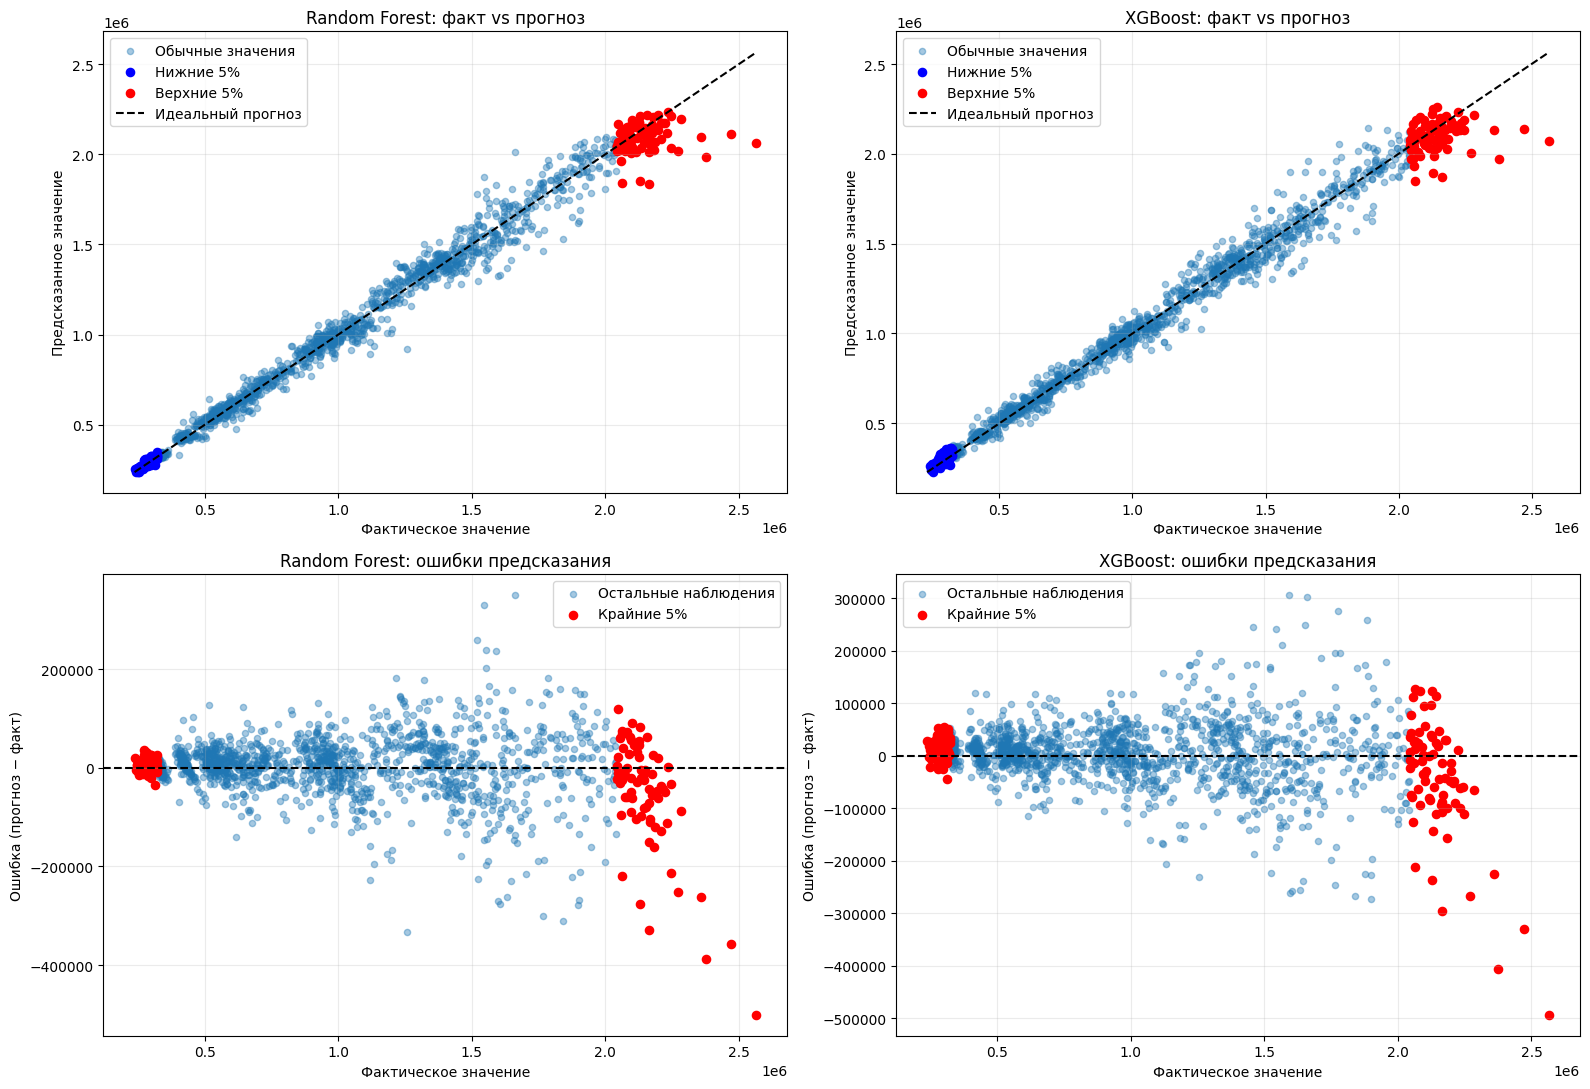

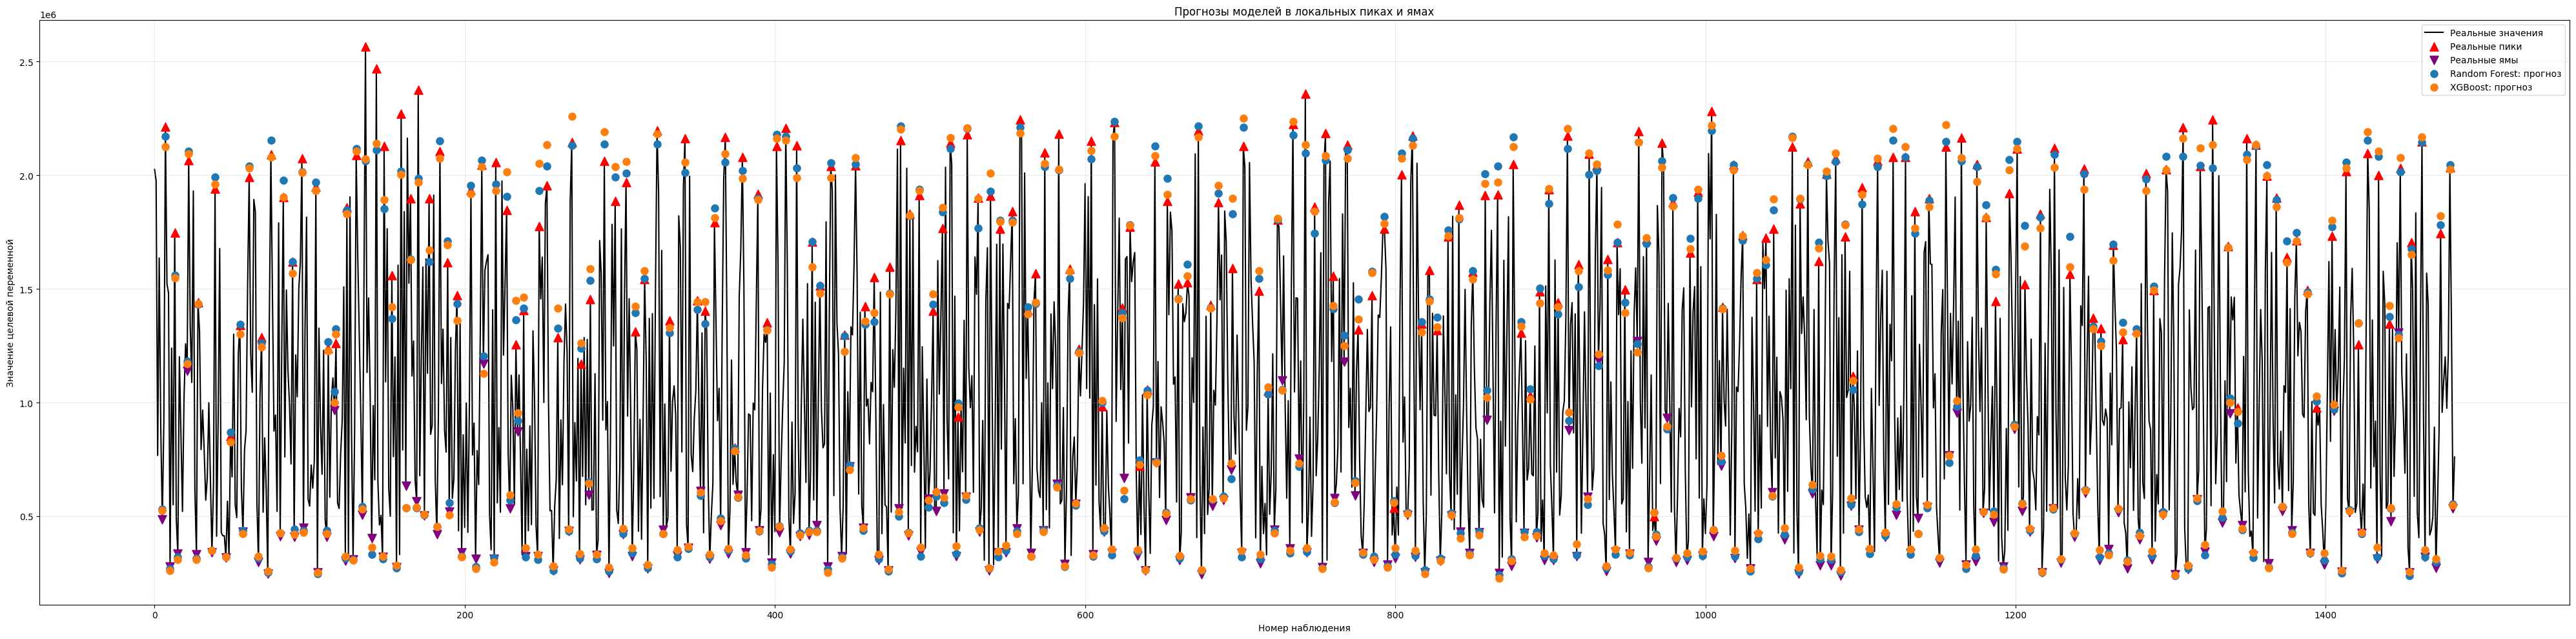

=== ОШИБКИ МОДЕЛЕЙ НА ЛОКАЛЬНЫХ ПИКАХ ===
 Индекс       Факт  Random Forest прогноз  Random Forest ошибка  Random Forest |ошибка|  XGBoost прогноз  XGBoost ошибка  XGBoost |ошибка|
    136 2565259.92            2064409.033           -500850.887              500850.887     2.072294e+06     -492966.420        492966.420
    143 2470206.13            2112522.037           -357684.093              357684.093     2.140311e+06     -329895.380        329895.380
    170 2376022.26            1987325.338           -388696.922              388696.922     1.970175e+06     -405847.260        405847.260
    742 2358055.30            2096929.792           -261125.508              261125.508     2.132965e+06     -225090.550        225090.550
   1004 2283540.30            2196254.945            -87285.355               87285.355     2.218247e+06      -65293.550         65293.550
    159 2271614.76            2018920.075           -252694.685              252694.685     2.004051e+06     -267564.135    

In [41]:

from scipy.signal import find_peaks

y_true = np.asarray(y_test).ravel()
x = np.arange(len(y_true))

predictions = {
    name: np.asarray(model.predict(X_test)).ravel()
    for name, model in models.items()
}

low_threshold, high_threshold = np.quantile(y_true, [0.05, 0.95])
low_mask = y_true <= low_threshold
high_mask = y_true >= high_threshold
extremum_mask = low_mask | high_mask

peaks, _ = find_peaks(y_true, distance=5, prominence=10000)
valleys, _ = find_peaks(-y_true, distance=5, prominence=10000)
extreme_indices = np.sort(np.concatenate([peaks, valleys]))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for col, (name, y_pred) in enumerate(predictions.items()):
    errors = y_pred - y_true

    ax = axes[0, col]
    ax.scatter(y_true, y_pred, alpha=0.4, s=20, label='Обычные значения')
    ax.scatter(y_true[low_mask], y_pred[low_mask], color='blue', s=35, label='Нижние 5%')
    ax.scatter(y_true[high_mask], y_pred[high_mask], color='red', s=35, label='Верхние 5%')

    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', label='Идеальный прогноз')

    ax.set(title=f'{name}: факт vs прогноз', xlabel='Фактическое значение',
           ylabel='Предсказанное значение')
    ax.legend()
    ax.grid(alpha=0.25)

    ax = axes[1, col]
    ax.scatter(y_true, errors, alpha=0.4, s=20, label='Остальные наблюдения')
    ax.scatter(y_true[extremum_mask], errors[extremum_mask],
               color='red', s=35, label='Крайние 5%')
    ax.axhline(0, color='black', linestyle='--')

    ax.set(title=f'{name}: ошибки предсказания',
           xlabel='Фактическое значение', ylabel='Ошибка (прогноз − факт)')
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(40, 10))

ax.plot(x, y_true, color='black', linewidth=1.5,
        label='Реальные значения', zorder=1)
ax.scatter(peaks, y_true[peaks], color='red', marker='^', s=90,
           label='Реальные пики', zorder=4)
ax.scatter(valleys, y_true[valleys], color='purple', marker='v', s=90,
           label='Реальные ямы', zorder=4)

for name, y_pred in predictions.items():
    ax.scatter(extreme_indices, y_pred[extreme_indices], s=65,
               label=f'{name}: прогноз', zorder=5)

ax.set(title='Прогнозы моделей в локальных пиках и ямах',
       xlabel='Номер наблюдения', ylabel='Значение целевой переменной')
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

peak_results = pd.DataFrame({
    'Индекс': peaks,
    'Факт': y_true[peaks]
})

for name, y_pred in predictions.items():
    errors = y_pred[peaks] - y_true[peaks]
    peak_results[f'{name} прогноз'] = y_pred[peaks]
    peak_results[f'{name} ошибка'] = errors
    peak_results[f'{name} |ошибка|'] = np.abs(errors)

peak_results = peak_results.sort_values('Факт', ascending=False)

print('=== ОШИБКИ МОДЕЛЕЙ НА ЛОКАЛЬНЫХ ПИКАХ ===')
print(peak_results.round(3).to_string(index=False))

summary = []

for name in predictions:
    abs_errors = peak_results[f'{name} |ошибка|']

    summary.append({
        'Модель': name,
        'Количество пиков': len(peak_results),
        'MAE': abs_errors.mean(),
        'RMSE': np.sqrt(np.mean(errors ** 2))
    })

summary_df = pd.DataFrame(summary)

print('\n=== СРЕДНИЕ ОШИБКИ МОДЕЛЕЙ НА ПИКАХ ===')
print(summary_df.round(3).to_string(index=False))




## 4. Встроенная важность признаков


Топ-15: Random Forest


,Признак,Важность,Модель
26,Sales_Lag_1,0.335220,Random Forest
30,Sales_Roll_Mean_4,0.320844,Random Forest
34,Sales_Expanding_Mean,0.222512,Random Forest
32,Sales_Roll_Mean_13,0.029542,Random Forest
28,Sales_Lag_4,0.026818,Random Forest
27,Sales_Lag_2,0.010471,Random Forest
23,Month_Cos,0.009332,Random Forest
16,Holiday_Thanksgiving,0.007158,Random Forest
17,Holiday_Black_Friday,0.006802,Random Forest
25,WeekOfYear_Cos,0.006688,Random Forest


Топ-15: XGBoost


,Признак,Важность,Модель
30,Sales_Roll_Mean_4,0.497241,XGBoost
34,Sales_Expanding_Mean,0.164123,XGBoost
26,Sales_Lag_1,0.105960,XGBoost
18,Holiday_Christmas,0.026548,XGBoost
84,Quarter_4,0.025469,XGBoost
16,Holiday_Thanksgiving,0.024521,XGBoost
21,Quarter_Cos,0.021748,XGBoost
32,Sales_Roll_Mean_13,0.017210,XGBoost
23,Month_Cos,0.016320,XGBoost
28,Sales_Lag_4,0.015682,XGBoost


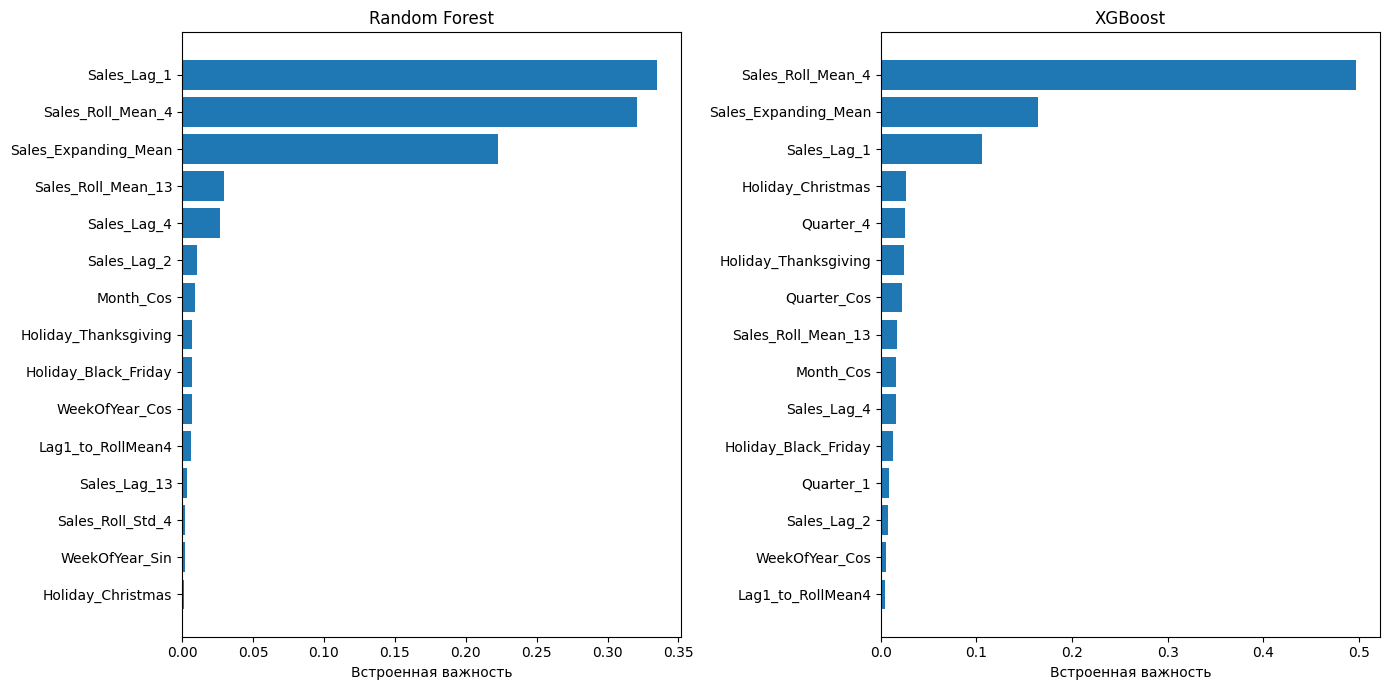

In [37]:
importance_frames = []
for name, model in models.items():
    values = model.feature_importances_
    frame = pd.DataFrame({'Признак': feature_cols, 'Важность': values})
    frame['Модель'] = name
    importance_frames.append(frame.sort_values('Важность', ascending=False))
    print(f'Топ-15: {name}')
    display(frame.sort_values('Важность', ascending=False).head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, frame in zip(axes, importance_frames):
    top = frame.nlargest(15, 'Важность').sort_values('Важность')
    ax.barh(top['Признак'], top['Важность'])
    ax.set_title(frame['Модель'].iloc[0])
    ax.set_xlabel('Встроенная важность')
plt.tight_layout()
OUT = Path('./results')
OUT.mkdir(exist_ok=True)
fig.savefig(OUT / 'feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. SHAP: анализ вкладов признаков


Топ-15 SHAP: Random Forest


,Признак,Среднее |SHAP|,Модель
26,Sales_Lag_1,192527.857469,Random Forest
30,Sales_Roll_Mean_4,155961.459457,Random Forest
34,Sales_Expanding_Mean,94010.690903,Random Forest
28,Sales_Lag_4,22157.668399,Random Forest
27,Sales_Lag_2,12422.270293,Random Forest
32,Sales_Roll_Mean_13,11441.118095,Random Forest
23,Month_Cos,6429.697186,Random Forest
35,Lag1_to_RollMean4,4506.378658,Random Forest
16,Holiday_Thanksgiving,4012.439627,Random Forest
17,Holiday_Black_Friday,3839.655295,Random Forest


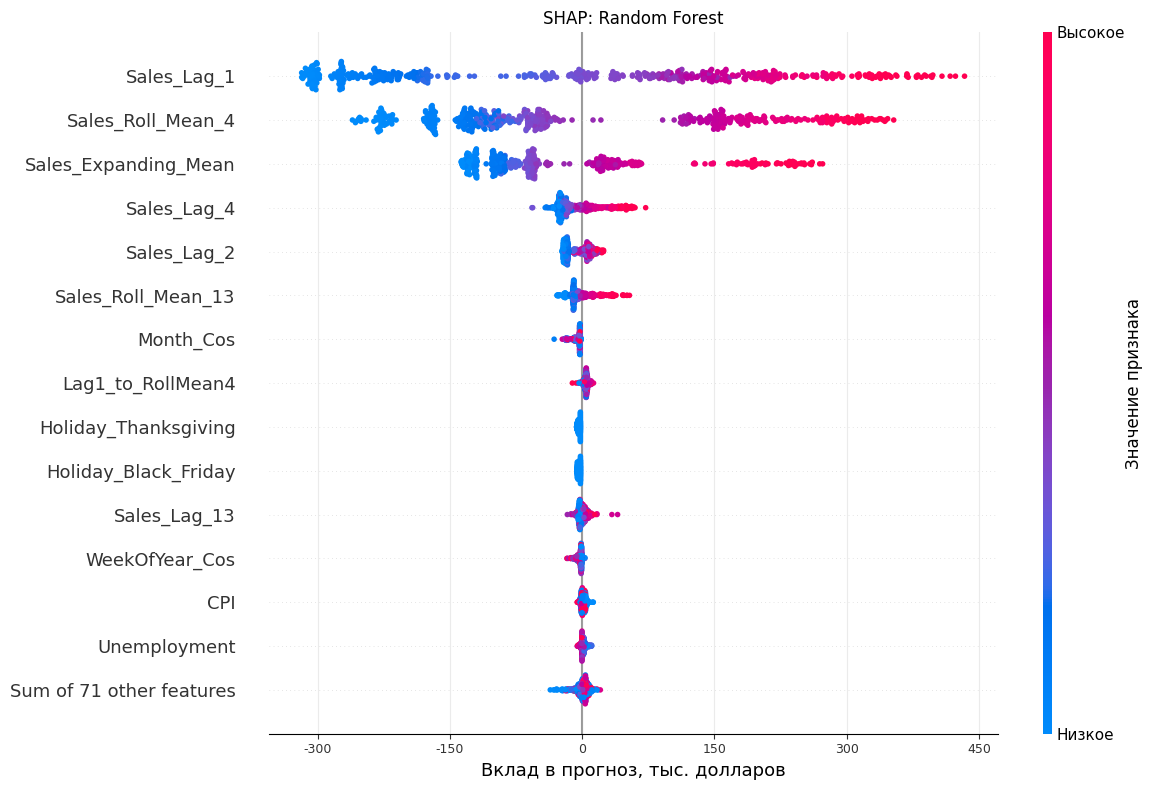

Топ-15 SHAP: XGBoost


,Признак,Среднее |SHAP|,Модель
30,Sales_Roll_Mean_4,165320.937500,XGBoost
26,Sales_Lag_1,146769.953125,XGBoost
34,Sales_Expanding_Mean,103071.773438,XGBoost
28,Sales_Lag_4,35468.062500,XGBoost
27,Sales_Lag_2,14374.365234,XGBoost
32,Sales_Roll_Mean_13,14127.516602,XGBoost
24,WeekOfYear_Sin,7814.554688,XGBoost
25,WeekOfYear_Cos,7732.804199,XGBoost
16,Holiday_Thanksgiving,6793.932617,XGBoost
35,Lag1_to_RollMean4,6447.429688,XGBoost


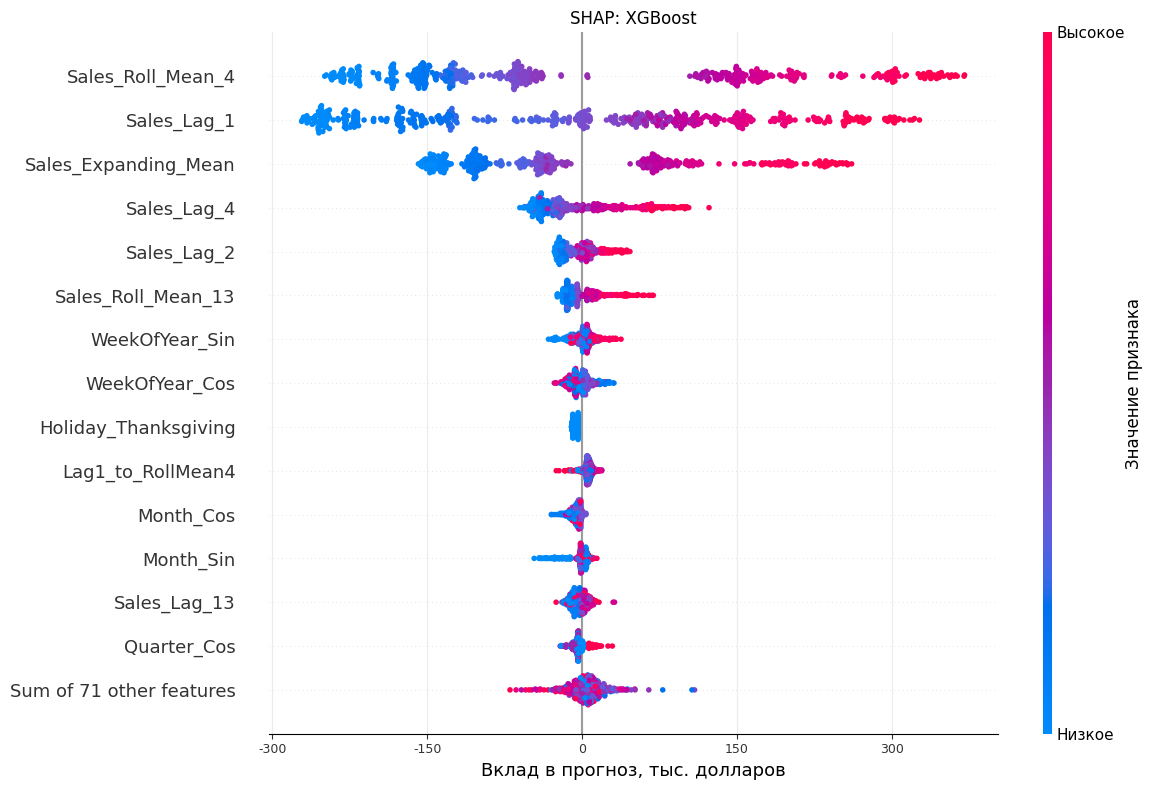

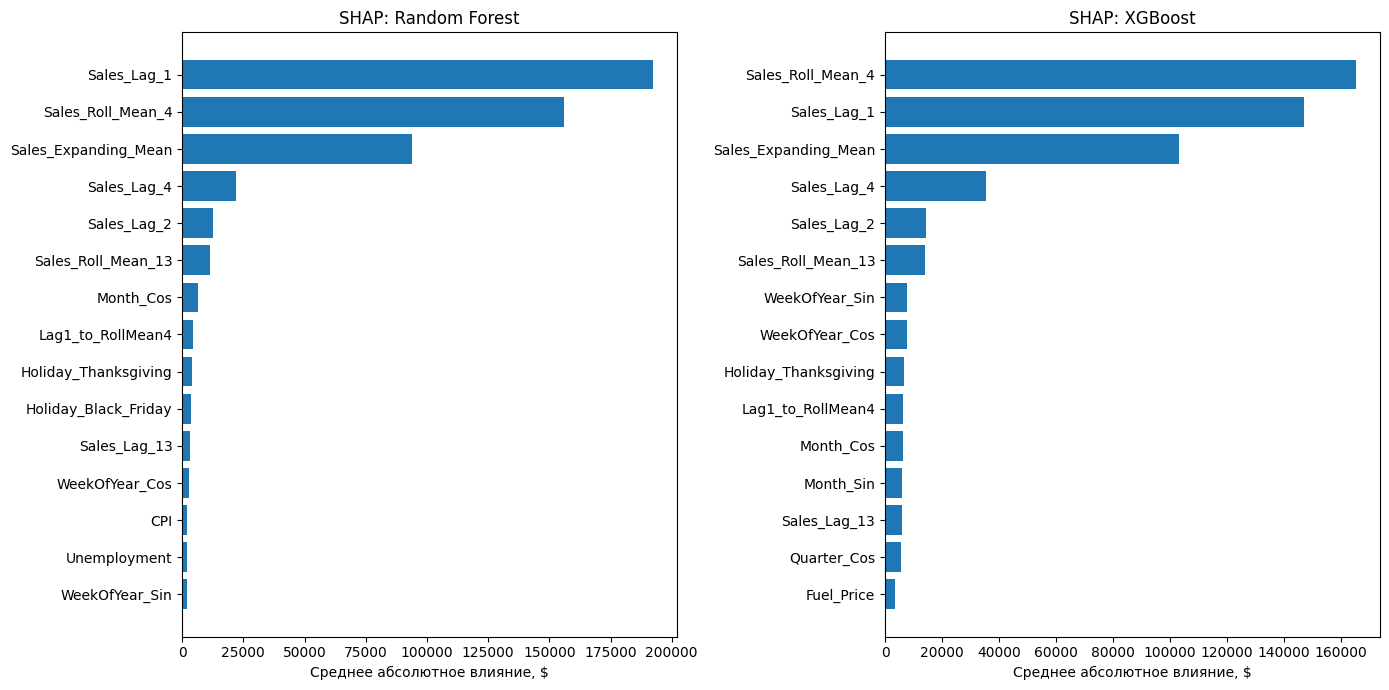

In [38]:
# Ограничиваем размер объясняемой выборки, сохраняя воспроизводимость.
X_explain = X_test.sample(n=min(500, len(X_valid)), random_state=42)
shap_frames = []
from matplotlib.ticker import FuncFormatter, MaxNLocator

for name, model in models.items():
    explainer = shap.TreeExplainer(model)
    explanation = explainer(X_explain)
    values = np.asarray(explanation.values)
    if values.ndim == 3:  # поддержка формата multi-output
        values = values[:, :, 0]
    mean_abs = np.abs(values).mean(axis=0)
    frame = pd.DataFrame({'Признак': feature_cols, 'Среднее |SHAP|': mean_abs})
    frame['Модель'] = name
    frame = frame.sort_values('Среднее |SHAP|', ascending=False)
    shap_frames.append(frame)
    print(f'Топ-15 SHAP: {name}')
    display(frame.head(15))

    shap.plots.beeswarm(explanation, max_display=15, show=False)
    fig = plt.gcf()
    fig.set_size_inches(12, 8)
    ax = fig.axes[0]
    ax.set_title(f'SHAP: {name}')
    ax.set_xlabel('Вклад в прогноз, тыс. долларов')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=7))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1000:.0f}'))
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(axis='x', alpha=0.25)
    if len(fig.axes) > 1:
        colorbar = fig.axes[-1]
        colorbar.set_ylabel('Значение признака')
        colorbar.set_yticks([0, 1], labels=['Низкое', 'Высокое'])
    fig.tight_layout()
    fig.savefig(OUT / f'shap_beeswarm_{name.lower().replace(" ", "_")}.png', dpi=150, bbox_inches='tight')
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, frame in zip(axes, shap_frames):
    top = frame.head(15).sort_values('Среднее |SHAP|')
    ax.barh(top['Признак'], top['Среднее |SHAP|'])
    ax.set_title(f"SHAP: {frame['Модель'].iloc[0]}")
    ax.set_xlabel('Среднее абсолютное влияние, $')
plt.tight_layout()
fig.savefig(OUT / 'shap_global_importance.png', dpi=150, bbox_inches='tight')
plt.show()


### Выводы по важности и SHAP


## 6. Финальная оценка на тестовом периоде


In [39]:
best_name = test_metrics.iloc[0]['Модель']
final_model = models[best_name]
test_result = metrics(y_test, final_model.predict(X_test))
print(f'Выбрана по test: {best_name}')
print(f"Финальный test: MAE={test_result['MAE']:,.2f}; RMSE={test_result['RMSE']:,.2f}; R²={test_result['R2']:.3f}")

# Сохраняем воспроизводимые таблицы и изображения.
test_metrics.to_csv(OUT / 'test_metrics.csv', index=False)
pd.DataFrame([{'Модель': best_name, **test_result}]).to_csv(OUT / 'test_metrics.csv', index=False)
pd.concat(importance_frames, ignore_index=True).to_csv(OUT / 'feature_importance.csv', index=False)
pd.concat(shap_frames, ignore_index=True).to_csv(OUT / 'shap_importance.csv', index=False)
print(f'Таблицы сохранены в {OUT.resolve()}')


Выбрана по test: XGBoost
Финальный test: MAE=42,999.93; RMSE=64,772.49; R²=0.985
Таблицы сохранены в C:\ITMO\основы анализа данных\lab2\results
